11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
              CNN - DIGIT RECOGNITION

Training data shape : (60000, 28, 28, 1)
Testing data shape  : (10000, 28, 28, 1)

CNN MODEL ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING CNN
Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 101ms/step - accuracy: 0.9361 - loss: 0.2182 - val_accuracy: 0.9815 - val_loss: 0.0651
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 99ms/step - accuracy: 0.9810 - loss: 0.0616 - val_accuracy: 0.9823 - val_loss: 0.0544
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.9860 - loss: 0.0432 - val_accuracy: 0.9873 - val_loss: 0.0453
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.9899 - loss: 0.0321 - val_accuracy: 0.9895 - val_loss: 0.0386
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9917 - loss: 0.0258 - val_accuracy: 0.9898 - val_loss: 0.0374
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9938 - loss: 0.0204 - val_accuracy: 0.9908 - val_loss: 0.0336
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9946 - loss: 0.0163 - val_accuracy: 0.9903 - val_loss: 0.0417
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9949 -

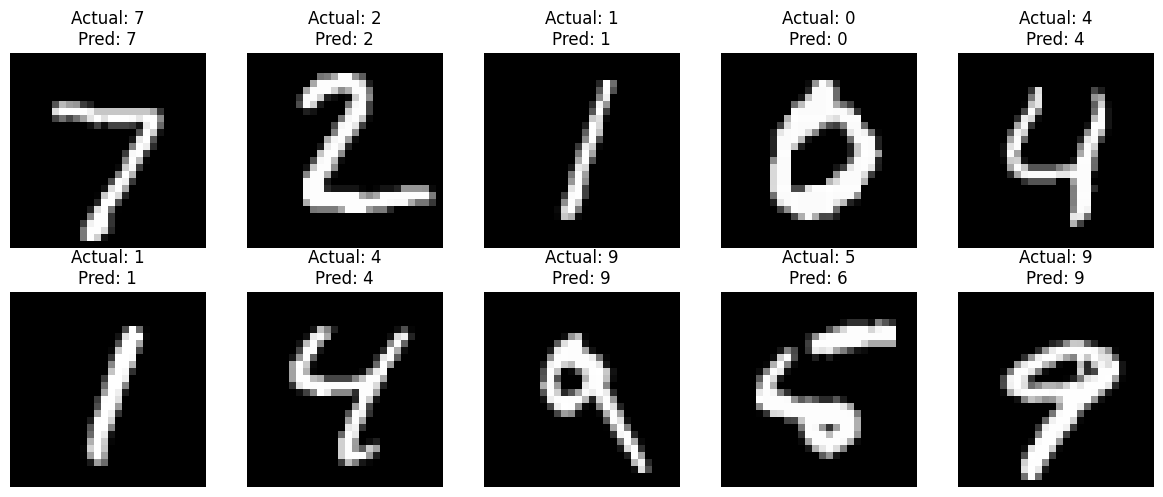

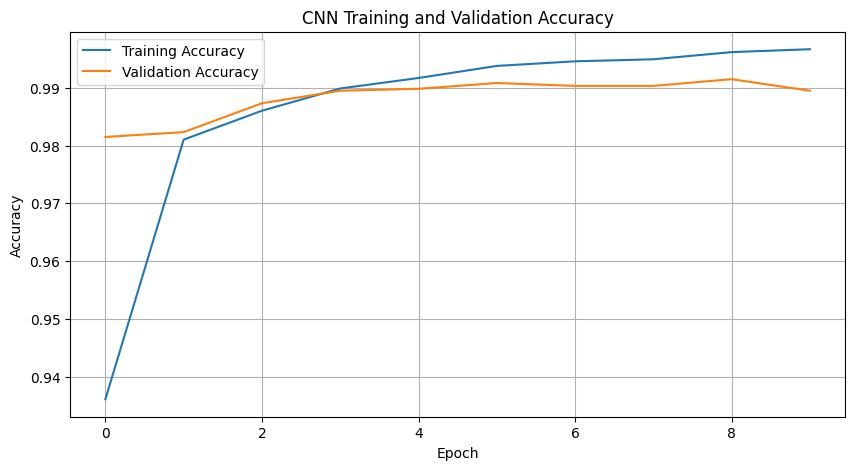

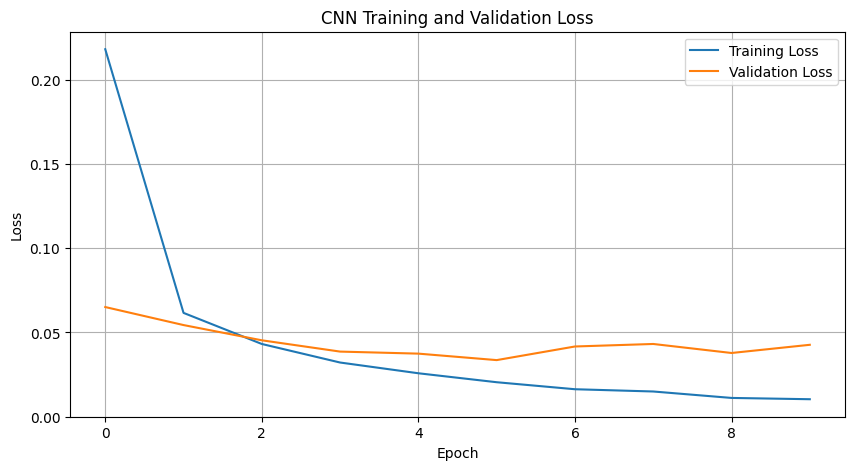

In [ ]:
# ============================================================
# CNN FOR HANDWRITTEN DIGIT RECOGNITION
# Dataset: MNIST
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD MNIST DATASET
# ============================================================

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()


# ============================================================
# 2. PREPROCESSING
# ============================================================

# Normalize pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension
# Original shape: (60000, 28, 28)
# New shape:      (60000, 28, 28, 1)

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)


print("=" * 70)
print("              CNN - DIGIT RECOGNITION")
print("=" * 70)

print("\nTraining data shape :", X_train.shape)
print("Testing data shape  :", X_test.shape)


# ============================================================
# 3. DESIGN CNN MODEL
# ============================================================

model = models.Sequential([

    # Input Layer
    layers.Input(shape=(28, 28, 1)),

    # --------------------------------------------------------
    # Convolution Layer 1
    # --------------------------------------------------------

    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # Pooling Layer 1
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # --------------------------------------------------------
    # Convolution Layer 2
    # --------------------------------------------------------

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # Pooling Layer 2
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # --------------------------------------------------------
    # Flatten
    # --------------------------------------------------------

    layers.Flatten(),

    # --------------------------------------------------------
    # Fully Connected Layer
    # --------------------------------------------------------

    layers.Dense(
        128,
        activation="relu"
    ),

    # --------------------------------------------------------
    # Output Layer
    # 10 neurons = digits 0 to 9
    # --------------------------------------------------------

    layers.Dense(
        10,
        activation="softmax"
    )
])


# ============================================================
# 4. DISPLAY MODEL ARCHITECTURE
# ============================================================

print("\nCNN MODEL ARCHITECTURE")
print("=" * 70)

model.summary()


# ============================================================
# 5. COMPILE MODEL
# ============================================================

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 6. TRAIN MODEL
# ============================================================

print("\nTRAINING CNN")
print("=" * 70)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


# ============================================================
# 7. EVALUATE MODEL
# ============================================================

print("\nMODEL EVALUATION")
print("=" * 70)

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")


# ============================================================
# 8. MAKE PREDICTIONS
# ============================================================

predictions = model.predict(
    X_test[:10],
    verbose=0
)

predicted_digits = predictions.argmax(axis=1)


# ============================================================
# 9. DISPLAY PREDICTIONS
# ============================================================

print("\nDIGIT PREDICTIONS")
print("=" * 70)

print(
    f"{'Image':^10} | "
    f"{'Actual':^10} | "
    f"{'Predicted':^10} | "
    f"{'Confidence':^12}"
)

print("-" * 70)

for i in range(10):

    confidence = predictions[i][predicted_digits[i]] * 100

    print(
        f"{i + 1:^10} | "
        f"{y_test[i]:^10} | "
        f"{predicted_digits[i]:^10} | "
        f"{confidence:^11.2f}%"
    )

print("-" * 70)


# ============================================================
# 10. DISPLAY SAMPLE DIGITS
# ============================================================

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Pred: {predicted_digits[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 11. PLOT TRAINING ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 12. PLOT TRAINING LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()